In [2]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [3]:
df=pd.read_csv("/Users/amansingh/Downloads/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<Axes: xlabel='Churn', ylabel='count'>

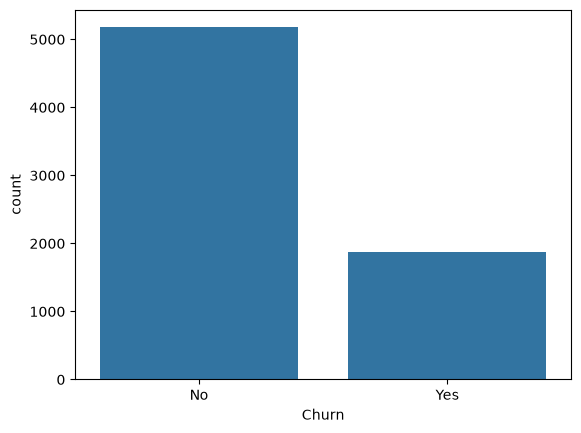

In [9]:
sns.countplot(x=df["Churn"])

In [10]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [11]:
df[df["TotalCharges"].str.strip() == ""].shape


(11, 21)

In [12]:
df["TotalCharges"] = df["TotalCharges"].str.strip().replace("", "0")
df["TotalCharges"] = df["TotalCharges"].astype("float")

In [13]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


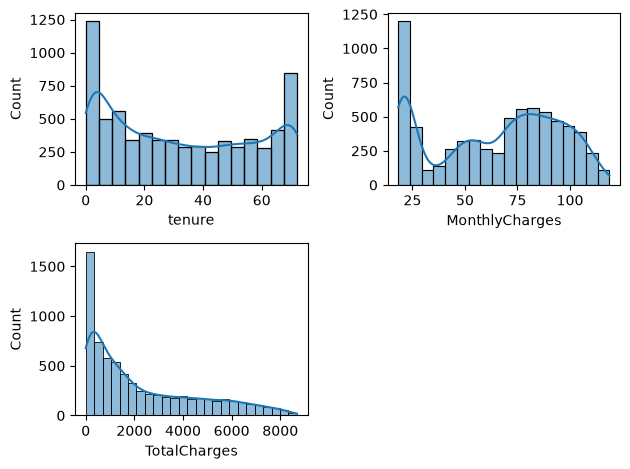

In [14]:
def plotting_numeric_values(num,var): 
    plt.subplot(2,2,num)
    sns.histplot(x=df[var],kde=True)

plotting_numeric_values(1,"tenure")
plotting_numeric_values(2,"MonthlyCharges")
plotting_numeric_values(3,"TotalCharges") 
plt.tight_layout()

<Axes: xlabel='tenure', ylabel='Churn'>

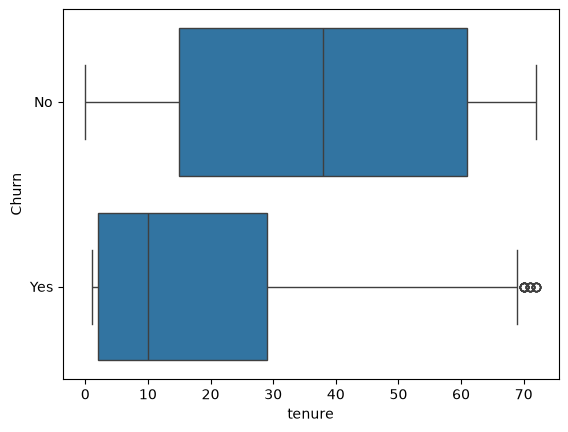

In [15]:
sns.boxplot(x=df["tenure"],y=df["Churn"])

<Axes: xlabel='MonthlyCharges', ylabel='Churn'>

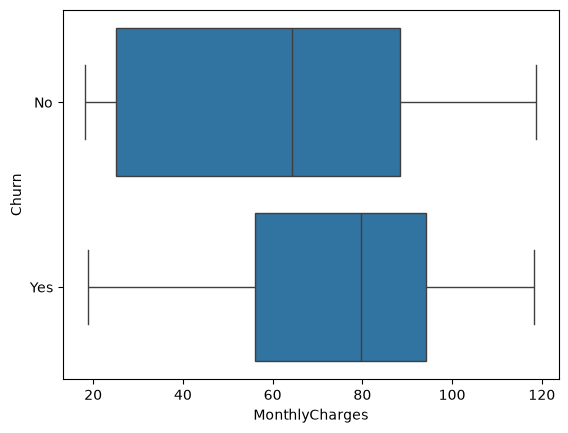

In [16]:
sns.boxplot(x=df["MonthlyCharges"],y=df["Churn"])

<Axes: xlabel='TotalCharges', ylabel='Churn'>

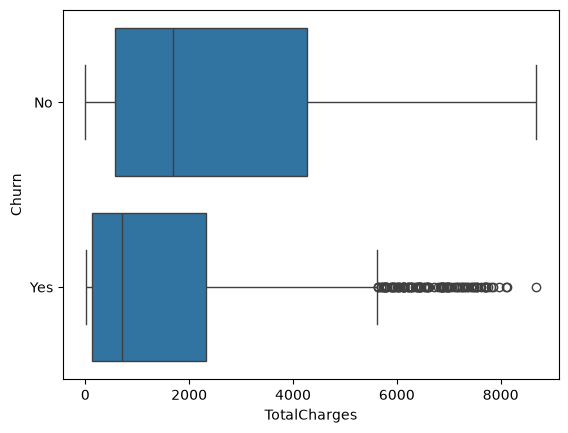

In [17]:
sns.boxplot(x=df["TotalCharges"],y=df["Churn"])

<Axes: xlabel='gender', ylabel='count'>

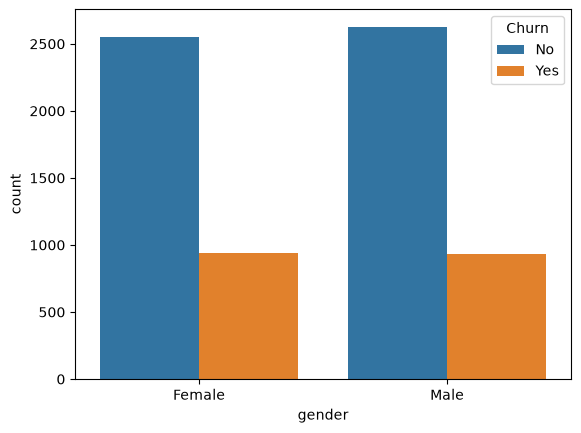

In [18]:
sns.countplot(x=df["gender"],hue=df["Churn"])

<Axes: xlabel='Partner', ylabel='count'>

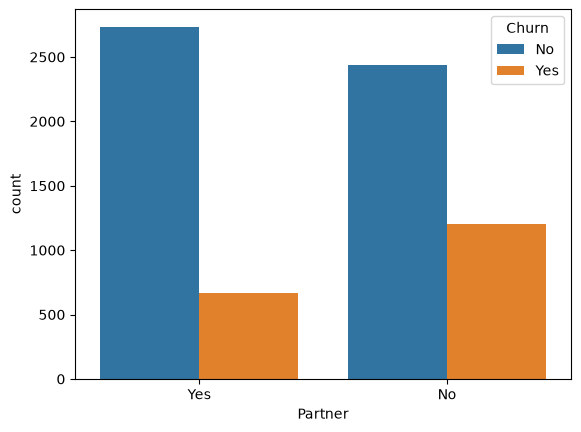

In [19]:
sns.countplot(x=df["Partner"],hue=df["Churn"])

<Axes: xlabel='MultipleLines', ylabel='count'>

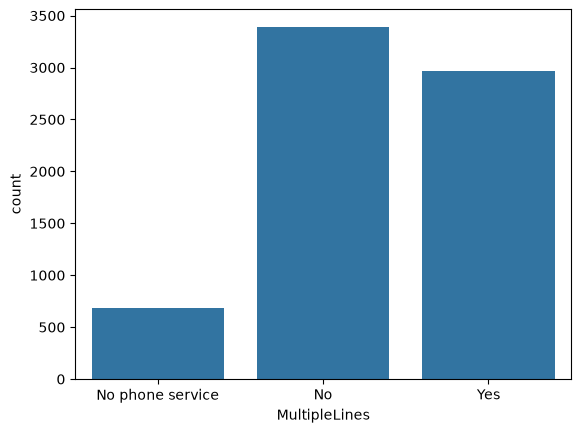

In [20]:
df["MultipleLines"].value_counts()
sns.countplot(x=df["MultipleLines"])

In [21]:
df=df.drop("customerID",axis=1) 


In [22]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [24]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

<Axes: xlabel='Contract', ylabel='count'>

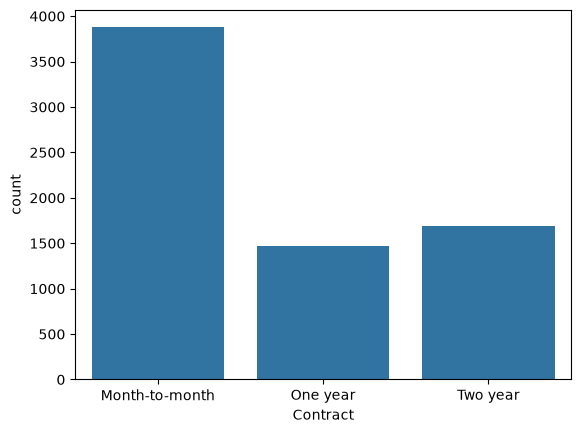

In [25]:
sns.countplot(x=df["Contract"])

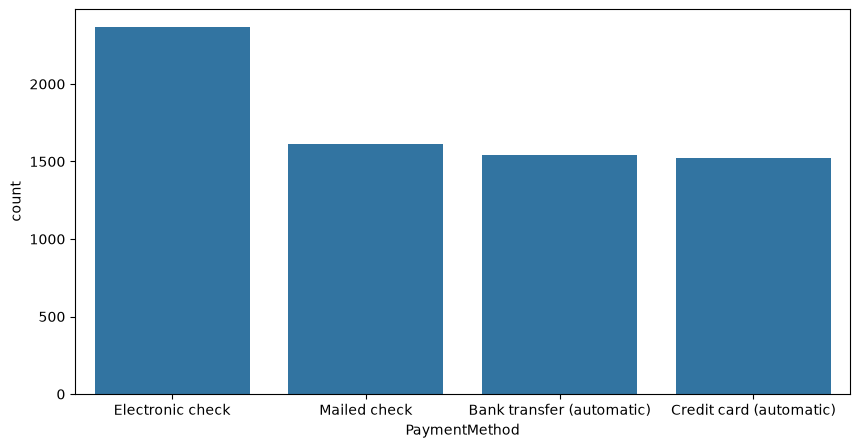

In [26]:
plt.figure(figsize=(10, 5))
sns.countplot(x=df["PaymentMethod"])
plt.show()

In [27]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [28]:
from scipy.stats import chi2_contingency
import pandas as pd

alpha = 0.05
cat_features=['gender','Partner', 'Dependents',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'] 

chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(df[col], df['Churn'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision =" "
    if p_val<alpha: 
        decision='Reject Null (Keep Feature)' 
    else: 
        decision= 'Accept Null (Drop Feature)'
        
   
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,Decision
Contract,1184.596572,0.0,Reject Null (Keep Feature)
OnlineSecurity,849.998968,0.0,Reject Null (Keep Feature)
TechSupport,828.197068,0.0,Reject Null (Keep Feature)
InternetService,732.30959,0.0,Reject Null (Keep Feature)
PaymentMethod,648.142327,0.0,Reject Null (Keep Feature)
OnlineBackup,601.81279,0.0,Reject Null (Keep Feature)
DeviceProtection,558.419369,0.0,Reject Null (Keep Feature)
StreamingMovies,375.661479,0.0,Reject Null (Keep Feature)
StreamingTV,374.203943,0.0,Reject Null (Keep Feature)
PaperlessBilling,258.277649,0.0,Reject Null (Keep Feature)


In [29]:
df=df.drop(df[["PhoneService","gender"]],axis=1) 
df.head()

,SeniorCitizen,Partner,Dependents,tenure,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Yes,No,1,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,0,No,No,34,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,0,No,No,2,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,0,No,No,45,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,0,No,No,2,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [30]:
df["Churn"]=df["Churn"].map({"No":0,"Yes":1})
df["Partner"]=df["Partner"].map({"Yes":1,"No":0})
df["Dependents"]=df["Dependents"].map({"Yes":1,"No":0})
df["PaperlessBilling"]=df["PaperlessBilling"].map({"Yes":1,"No":0})
df.rename(columns={"gender": "is_Male"}, inplace=True)

In [31]:
df.head()

,SeniorCitizen,Partner,Dependents,tenure,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,1,0,1,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,0,0,0,34,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,0,0,0,2,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,0,0,0,45,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,2,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SeniorCitizen     7043 non-null   int64  
 1   Partner           7043 non-null   int64  
 2   Dependents        7043 non-null   int64  
 3   tenure            7043 non-null   int64  
 4   MultipleLines     7043 non-null   str    
 5   InternetService   7043 non-null   str    
 6   OnlineSecurity    7043 non-null   str    
 7   OnlineBackup      7043 non-null   str    
 8   DeviceProtection  7043 non-null   str    
 9   TechSupport       7043 non-null   str    
 10  StreamingTV       7043 non-null   str    
 11  StreamingMovies   7043 non-null   str    
 12  Contract          7043 non-null   str    
 13  PaperlessBilling  7043 non-null   int64  
 14  PaymentMethod     7043 non-null   str    
 15  MonthlyCharges    7043 non-null   float64
 16  TotalCharges      7043 non-null   float64
 17  Churn 

In [33]:
df_corr=df[["tenure","MonthlyCharges","TotalCharges","Churn"]].corr()


In [34]:
df_corr

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.000000,0.247900,0.826178,-0.352229
MonthlyCharges,0.247900,1.000000,0.651174,0.193356
TotalCharges,0.826178,0.651174,1.000000,-0.198324
Churn,-0.352229,0.193356,-0.198324,1.000000


<Axes: >

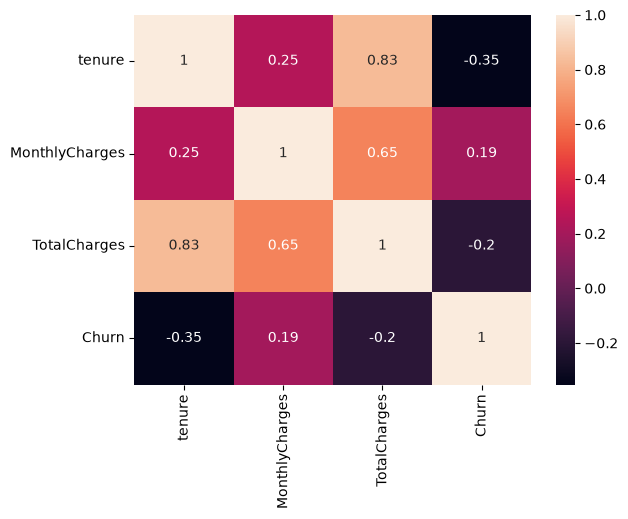

In [35]:
sns.heatmap(df_corr,annot=True) 

In [36]:
df.head()

,SeniorCitizen,Partner,Dependents,tenure,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,1,0,1,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,0,0,0,34,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,0,0,0,2,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,0,0,0,45,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,2,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [37]:
df.columns

Index(['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges',
       'Churn'],
      dtype='str')

In [38]:
nominal_columns = [
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "PaymentMethod", 
    "Contract"
]
df = pd.get_dummies(
    df,
    columns=nominal_columns,
    dtype=int
)


In [39]:
df.head()

,SeniorCitizen,Partner,Dependents,tenure,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No,MultipleLines_No phone service,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_Month-to-month,Contract_One year,Contract_Two year
0,0,1,0,1,1,29.85,29.85,0,0,1,...,1,0,0,0,0,1,0,1,0,0
1,0,0,0,34,0,56.95,1889.50,0,1,0,...,1,0,0,0,0,0,1,0,1,0
2,0,0,0,2,1,53.85,108.15,1,1,0,...,1,0,0,0,0,0,1,1,0,0
3,0,0,0,45,0,42.30,1840.75,0,0,1,...,1,0,0,1,0,0,0,0,1,0
4,0,0,0,2,1,70.70,151.65,1,1,0,...,1,0,0,0,0,1,0,1,0,0


In [40]:
df.columns

Index(['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PaperlessBilling',
       'MonthlyCharges', 'TotalCharges', 'Churn', 'MultipleLines_No',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'Co

In [79]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score 

numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]
x = df.drop("Churn", axis=1)
y = df["Churn"]
x_original=x
y_original=y
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42) 

scalar = StandardScaler() 

x_train[numeric_columns]=scalar.fit_transform(x_train[numeric_columns])
x_test[numeric_columns]=scalar.fit_transform(x_test[numeric_columns])

In [42]:
x_train

,SeniorCitizen,Partner,Dependents,tenure,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_Month-to-month,Contract_One year,Contract_Two year
2142,0,0,1,-0.465683,0,-0.000474,-0.419925,1,0,0,...,0,0,1,0,0,0,1,0,1,0
1623,0,0,0,0.885537,1,1.074754,1.256017,0,0,1,...,0,0,1,1,0,0,0,0,0,1
6074,0,1,0,-1.284605,1,-1.376499,-1.000283,0,1,0,...,1,0,0,0,0,1,0,1,0,0
1362,0,0,0,-1.161766,1,0.177346,-0.905497,1,0,0,...,1,0,0,0,0,1,0,1,0,0
6754,0,0,1,-1.325551,1,-0.098524,-1.010646,0,0,1,...,1,0,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3772,0,1,0,-1.284605,1,1.001632,-0.968666,1,0,0,...,0,0,1,0,0,1,0,1,0,0
5191,0,1,1,-0.383791,1,0.872006,-0.039235,0,0,1,...,0,0,1,0,1,0,0,0,0,1
5226,0,1,1,-0.834198,1,-1.452945,-0.875405,1,0,0,...,0,1,0,0,0,1,0,1,0,0
5390,1,0,0,-0.834198,1,1.149538,-0.480309,0,0,1,...,0,0,1,0,0,1,0,1,0,0


In [43]:
x.columns

Index(['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PaperlessBilling',
       'MonthlyCharges', 'TotalCharges', 'MultipleLines_No',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'Contract_Mo

In [44]:
x.head()

,SeniorCitizen,Partner,Dependents,tenure,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_Month-to-month,Contract_One year,Contract_Two year
0,0,1,0,1,1,29.85,29.85,0,1,0,...,1,0,0,0,0,1,0,1,0,0
1,0,0,0,34,0,56.95,1889.50,1,0,0,...,1,0,0,0,0,0,1,0,1,0
2,0,0,0,2,1,53.85,108.15,1,0,0,...,1,0,0,0,0,0,1,1,0,0
3,0,0,0,45,0,42.30,1840.75,0,1,0,...,1,0,0,1,0,0,0,0,1,0
4,0,0,0,2,1,70.70,151.65,1,0,0,...,1,0,0,0,0,1,0,1,0,0


In [45]:
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
model_Lr=LinearRegression() 
model_Lr.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](38,)","[ 0.04, 0.01,-0.02,..., 0.06,-0.04,-0.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](38,)","['SeniorCitizen','Partner','Dependents',...,'Contract_Month-to-month', 'Contract_One year','Contract_Two year']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.1156
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,38
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(22)


In [46]:
y_predict_Lr = model_Lr.predict(x_test)

r2 = r2_score(y_test, y_predict_Lr)

n = x_test.shape[0]
p = x_test.shape[1]

adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("R2:", r2)
print("Adjusted R2:", adjusted_r2)

R2: 0.3112002209237179
Adjusted R2: 0.2920948255916751


In [47]:
from sklearn.linear_model import LogisticRegression 
from sklearn.naive_bayes import GaussianNB 
from sklearn.tree import DecisionTreeClassifier 
from sklearn.svm import SVC 
from sklearn.neighbors import KNeighborsClassifier  
from sklearn.metrics import accuracy_score, confusion_matrix , classification_report,f1_score
models={"logistic Regression":LogisticRegression(max_iter=1000), 
        "KNN":KNeighborsClassifier(), 
        "Naive Bayes": GaussianNB(), 
        "Decesion Tree": DecisionTreeClassifier(), 
        "SVM":SVC(kernel="rbf")
       }
result=[] 
for name,models in models.items(): 
    models.fit(x_train,y_train) 
    y_pred=models.predict(x_test) 
    acc=accuracy_score(y_test,y_pred) 
    f1=f1_score(y_test,y_pred)
    result.append({"model":name, 
                   "Accuracy":round(acc,4), 
                   "f1_score":round(f1,4)})
result

[{'model': 'logistic Regression', 'Accuracy': 0.8219, 'f1_score': 0.6368},
 {'model': 'KNN', 'Accuracy': 0.775, 'f1_score': 0.5516},
 {'model': 'Naive Bayes', 'Accuracy': 0.6977, 'f1_score': 0.6041},
 {'model': 'Decesion Tree', 'Accuracy': 0.7168, 'f1_score': 0.442},
 {'model': 'SVM', 'Accuracy': 0.8141, 'f1_score': 0.5944}]

In [48]:
from sklearn.model_selection import cross_val_score 
accuracy_after_cross_validation={}
models={"logistic Regression":LogisticRegression(), 
        "KNN":KNeighborsClassifier(), 
        "Naive Bayes": GaussianNB(), 
        "Decision Tree": DecisionTreeClassifier(), 
        "SVM":SVC(kernel="rbf")
       }
for name,model in models.items(): 
    model.fit(x_train,y_train)
    x_scaled=x
    x_scaled[numeric_columns]=scalar.fit_transform(df[numeric_columns])
    scores=cross_val_score(model,x,y,cv=5,scoring="accuracy")
    accuracy_after_cross_validation[name]=scores.mean()
print("the final accuraccy after the cross validation for the models are - ")
results = pd.DataFrame(
    list(accuracy_after_cross_validation.items()),
    columns=["Model", "Mean Accuracy"]
).sort_values(by="Mean Accuracy", ascending=False)

results

the final accuraccy after the cross validation for the models are - 


,Model,Mean Accuracy
0,logistic Regression,0.803920
4,SVM,0.799376
1,KNN,0.770412
3,Decision Tree,0.726819
2,Naive Bayes,0.692459


In [49]:
from sklearn.model_selection import GridSearchCV
models={"logistic Regression":LogisticRegression(), 
        "KNN":KNeighborsClassifier(), 
        "Naive Bayes": GaussianNB(), 
        "Decision Tree": DecisionTreeClassifier(), 
        "SVM":SVC(kernel="rbf")
       }
param_grid = {
    "logistic Regression": {
        "C": [0.01, 0.1, 1, 10, 100],
        "solver": ["lbfgs"],
        "class_weight": [None, "balanced"]
    },

    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    },

    "Naive Bayes": {
        "var_smoothing": [1e-11, 1e-10, 1e-9, 1e-8, 1e-7]
    },

    "Decision Tree": {
        "criterion": ["gini", "entropy"],
        "max_depth": [None, 5, 10, 15, 20],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4]
    },

    "SVM": {
        "C": [0.1, 1, 10, 100],
        "kernel": ["linear", "rbf"],
        "gamma": ["scale", "auto"],
        "class_weight": [None, "balanced"]
    }
}

In [51]:
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import RandomizedSearchCV
results = {}

for name, parameters in param_grid.items():

    n = 5 if name == "Naive Bayes" else 10

    classifier = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=parameters,
        n_iter=n,
        cv=5,
        scoring="accuracy",
        return_train_score=False,
        random_state=42,
        n_jobs=-1
    )

    classifier.fit(x_train, y_train)

    # Predict using the best model
    y_pred = classifier.best_estimator_.predict(x_test)

    results[name] = {
        "Best Parameters": classifier.best_params_,
        "Best CV Accuracy": classifier.best_score_,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred, average="weighted")
    }

result = pd.DataFrame.from_dict(results, orient="index")
result.index.name = "Model Name"
result = result.reset_index()
prev_result=result
display(prev_result)

,Model Name,Best Parameters,Best CV Accuracy,Test Accuracy,F1 Score
0,logistic Regression,"{'solver': 'lbfgs', 'class_weight': None, 'C':...",0.802272,0.818311,0.813126
1,KNN,"{'weights': 'uniform', 'p': 2, 'n_neighbors': 11}",0.779908,0.796309,0.792573
2,Naive Bayes,{'var_smoothing': 1e-11},0.687968,0.697658,0.715383
3,Decision Tree,"{'min_samples_split': 5, 'min_samples_leaf': 1...",0.786653,0.802697,0.802697
4,SVM,"{'kernel': 'linear', 'gamma': 'scale', 'class_...",0.797303,0.820440,0.815616


In [52]:
#Accurracy Improvement using the ensemble learning techniques- 
from sklearn.ensemble import StackingClassifier
x1_train,x1_test,y1_train,y1_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y) 
x1_train[numeric_columns]=scalar.fit_transform(x1_train[numeric_columns])
x1_test[numeric_columns]=scalar.fit_transform(x1_test[numeric_columns])

In [53]:
Base_learners=[
                ("dt",DecisionTreeClassifier(random_state=42)), 
                ("svc",SVC(kernel="rbf",random_state=42)), 
                ("lr",LogisticRegression(max_iter=10000))
               ]

In [54]:
meta_learner=LogisticRegression(max_iter=1000) 
stacking_clf=StackingClassifier(
              estimators=Base_learners, 
              final_estimator=meta_learner, 
              cv=5
               )


In [55]:
stacking_clf.fit(x1_train,y1_train) 


,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('dt', ...), ('svc', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=1000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[DecisionTreeC...ndom_state=42), SVC(random_state=42), LogisticRegre...ax_iter=10000)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","

In [56]:
y1_pred=stacking_clf.predict(x1_test) 
accuracy=accuracy_score(y1_test,y1_pred) 
accuracy

0.801277501774308

In [57]:
#Through Random forest classifier 
from sklearn.ensemble import RandomForestClassifier 
rf_model=RandomForestClassifier(n_estimators=100,max_depth=None,random_state=42) 
rf_model.fit(x1_train,y1_train) 
y1_pred=rf_model.predict(x1_test) 
accuracy=accuracy_score(y1_test,y1_pred) 
accuracy 


0.7778566359119943

In [58]:
%pip install xgboost


Note: you may need to restart the kernel to use updated packages.


In [59]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

In [60]:
ada_model=AdaBoostClassifier(n_estimators=100,random_state=42) 
ada_model.fit(x1_train,y1_train) 
y1_pred=ada_model.predict(x1_test) 
accuracy=accuracy_score(y1_test,y1_pred) 
accuracy

0.7963094393186657

In [61]:
gb_model=GradientBoostingClassifier(n_estimators=100,learning_rate=0.1,random_state=42) 
gb_model.fit(x1_train,y1_train) 
y1_pred=gb_model.predict(x1_test)
accuracy=accuracy_score(y1_test,y1_pred) 
accuracy

0.8026969481902059

In [62]:
xgb_model=XGBClassifier(n_estimators=100,learning_rate=0.1,max_depth=3,eval_metric="logloss",random_state=42) 
xgb_model.fit(x1_train,y1_train) 

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [63]:
y1_pred=xgb_model.predict(x1_test) 
accuracy=accuracy_score(y1_test,y1_pred) 
accuracy

0.8048261178140526

In [64]:
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
stacking_params = {
    "dt__max_depth": [None, 5, 10, 20],
    "dt__min_samples_split": [2, 5, 10],
    "dt__min_samples_leaf": [1, 2, 4],
    "svc__C": [0.1, 1, 10],
    "svc__gamma": ["scale", "auto"],
    "final_estimator__C": [0.1, 1, 10]
}

stacking_search = RandomizedSearchCV(
    estimator=stacking_clf,
    param_distributions=stacking_params,
    n_iter=20,
    scoring="f1_weighted",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)


stacking_search.fit(x1_train, y1_train)

 # Predict using the best model
best_stacking_model = stacking_search.best_estimator_
y1_pred = best_stacking_model.predict(x1_test)

# Calculate mean CV accuracy for the selected model
cv_accuracy = cross_val_score(
    best_stacking_model,
    x1_train,
    y1_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
).mean()

# Store results
result_1 = {
    "Best Parameters": stacking_search.best_params_,
    "Best CV Accuracy": cv_accuracy,
    "Best CV Weighted F1": stacking_search.best_score_,
    "Test Accuracy": accuracy_score(y1_test, y1_pred),
    "Test F1 Score (Weighted)": f1_score(
        y1_test, y1_pred, average="weighted"
    ),
    "Test F1 Score (Macro)": f1_score(
        y1_test, y1_pred, average="macro"
    )
}

print("Best Stacking Parameters:", stacking_search.best_params_)
print(result_1)

Best Stacking Parameters: {'svc__gamma': 'auto', 'svc__C': 10, 'final_estimator__C': 1, 'dt__min_samples_split': 2, 'dt__min_samples_leaf': 4, 'dt__max_depth': 20}
{'Best Parameters': {'svc__gamma': 'auto', 'svc__C': 10, 'final_estimator__C': 1, 'dt__min_samples_split': 2, 'dt__min_samples_leaf': 4, 'dt__max_depth': 20}, 'Best CV Accuracy': np.float64(0.8067111005341205), 'Best CV Weighted F1': np.float64(0.7991687852189167), 'Test Accuracy': 0.8005677785663591, 'Test F1 Score (Weighted)': 0.7922133258257805, 'Test F1 Score (Macro)': 0.7240368658069849}


In [65]:
rf_params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_params,
    n_iter=20,
    scoring="f1_weighted",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

rf_search.fit(x1_train, y1_train)

best_rf_model = rf_search.best_estimator_
y1_pred = best_rf_model.predict(x1_test)

# Calculate mean CV accuracy for the selected model
cv_accuracy = cross_val_score(
    best_rf_model,
    x1_train,
    y1_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
).mean()

# Store results
result_2 = {
    "Best Parameters": rf_search.best_params_,
    "Best CV Accuracy": cv_accuracy,
    "Best CV Weighted F1": rf_search.best_score_,
    "Test Accuracy": accuracy_score(y1_test, y1_pred),
    "Test F1 Score (Weighted)": f1_score(
        y1_test, y1_pred, average="weighted"
    ),
    "Test F1 Score (Macro)": f1_score(
        y1_test, y1_pred, average="macro"
    )
}
print(result_2)

{'Best Parameters': {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10}, 'Best CV Accuracy': np.float64(0.8028064573578293), 'Best CV Weighted F1': np.float64(0.7943070563012216), 'Test Accuracy': 0.801277501774308, 'Test F1 Score (Weighted)': 0.7923329342840083, 'Test F1 Score (Macro)': 0.7235845725271707}


In [66]:
ada_model = AdaBoostClassifier(random_state=42)

ada_params = {
    "n_estimators": [50, 100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0],
    "estimator": [
        DecisionTreeClassifier(max_depth=1, random_state=42),
        DecisionTreeClassifier(max_depth=2, random_state=42),
        DecisionTreeClassifier(max_depth=3, random_state=42)
    ]
}

ada_search = RandomizedSearchCV(
    estimator=ada_model,
    param_distributions=ada_params,
    n_iter=20,
    scoring="f1_weighted",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

ada_search.fit(x1_train, y1_train)

best_ada_search_model = ada_search.best_estimator_
y1_pred = best_ada_search_model.predict(x1_test)

# Calculate mean CV accuracy for the selected model
cv_accuracy = cross_val_score(
    best_ada_search_model,
    x1_train,
    y1_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
).mean()

# Store results
result_3 = {
    "Best Parameters": ada_search.best_params_,
    "Best CV Accuracy": cv_accuracy,
    "Best CV Weighted F1": ada_search.best_score_,
    "Test Accuracy": accuracy_score(y1_test, y1_pred),
    "Test F1 Score (Weighted)": f1_score(
        y1_test, y1_pred, average="weighted"
    ),
    "Test F1 Score (Macro)": f1_score(
        y1_test, y1_pred, average="macro"
    )
}
print(result_3)

{'Best Parameters': {'n_estimators': 300, 'learning_rate': 0.1, 'estimator': DecisionTreeClassifier(max_depth=2, random_state=42)}, 'Best CV Accuracy': np.float64(0.8063566487680871), 'Best CV Weighted F1': np.float64(0.7991235036867546), 'Test Accuracy': 0.7934705464868701, 'Test F1 Score (Weighted)': 0.7807317858543723, 'Test F1 Score (Macro)': 0.7048730401058954}


In [67]:

gb_model = GradientBoostingClassifier(random_state=42)

gb_params = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 5],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "subsample": [0.7, 0.8, 1.0]
}

gb_search = RandomizedSearchCV(
    estimator=gb_model,
    param_distributions=gb_params,
    n_iter=20,
    scoring="f1_weighted",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

gb_search.fit(x1_train, y1_train)

best_gb_search_model = gb_search.best_estimator_
y1_pred = best_gb_search_model.predict(x1_test)

# Calculate mean CV accuracy for the selected model
cv_accuracy = cross_val_score(
    best_gb_search_model,
    x1_train,
    y1_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
).mean()

# Store results
result_4 = {
    "Best Parameters": gb_search.best_params_,
    "Best CV Accuracy": cv_accuracy,
    "Best CV Weighted F1": gb_search.best_score_,
    "Test Accuracy": accuracy_score(y1_test, y1_pred),
    "Test F1 Score (Weighted)": f1_score(
        y1_test, y1_pred, average="weighted"
    ),
    "Test F1 Score (Macro)": f1_score(
        y1_test, y1_pred, average="macro"
    )
}
print(result_4)


{'Best Parameters': {'subsample': 0.8, 'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 2, 'learning_rate': 0.05}, 'Best CV Accuracy': np.float64(0.807065237091825), 'Best CV Weighted F1': np.float64(0.796906123379719), 'Test Accuracy': 0.794180269694819, 'Test F1 Score (Weighted)': 0.7789272932330937, 'Test F1 Score (Macro)': 0.7001599694737151}


In [68]:
xgb_model = XGBClassifier(
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

xgb_params = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 4, 5, 7],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "gamma": [0, 0.1, 0.3]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_params,
    n_iter=20,
    scoring="f1_weighted",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

xgb_search.fit(x1_train, y1_train)

best_xgb_search_model = xgb_search.best_estimator_
y1_pred = best_xgb_search_model.predict(x1_test)

# Calculate mean CV accuracy for the selected model
cv_accuracy = cross_val_score(
    best_xgb_search_model,
    x1_train,
    y1_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
).mean()

# Store results
result_5 = {
    "Best Parameters": xgb_search.best_params_,
    "Best CV Accuracy": cv_accuracy,
    "Best CV Weighted F1": xgb_search.best_score_,
    "Test Accuracy": accuracy_score(y1_test, y1_pred),
    "Test F1 Score (Weighted)": f1_score(
        y1_test, y1_pred, average="weighted"
    ),
    "Test F1 Score (Macro)": f1_score(
        y1_test, y1_pred, average="macro"
    )
}
print(result_5)


{'Best Parameters': {'subsample': 0.8, 'n_estimators': 100, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 0.7}, 'Best CV Accuracy': np.float64(0.8054687069051113), 'Best CV Weighted F1': np.float64(0.7974989864030284), 'Test Accuracy': 0.8019872249822569, 'Test F1 Score (Weighted)': 0.7936922345387643, 'Test F1 Score (Macro)': 0.7260010162282875}


In [69]:
models = {
    "Stacking": stacking_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "AdaBoost": ada_search.best_estimator_,
    "Gradient Boosting": gb_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_
}

results = []

for name, model in models.items():
    y_pred = model.predict(x1_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y1_test, y_pred),
        "F1 Score (Weighted)": f1_score(
            y1_test, y_pred, average="weighted"
        ),
        "F1 Score (Macro)": f1_score(
            y1_test, y_pred, average="macro"
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score (Weighted)",
    ascending=False
).reset_index(drop=True)

# Display as a DataFrame rounded to 4 decimal places
display(results_df.round(4))

,Model,Accuracy,F1 Score (Weighted),F1 Score (Macro)
0,XGBoost,0.8020,0.7937,0.7260
1,Random Forest,0.8013,0.7923,0.7236
2,Stacking,0.8006,0.7922,0.7240
3,AdaBoost,0.7935,0.7807,0.7049
4,Gradient Boosting,0.7942,0.7789,0.7002


In [70]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import cross_val_score

searches = {
    "Stacking": stacking_search,
    "Random Forest": rf_search,
    "AdaBoost": ada_search,
    "Gradient Boosting": gb_search,
    "XGBoost": xgb_search
}

all_results = []

for name, search in searches.items():

    # Best model for this search
    best_model = search.best_estimator_

    # Predict using this model
    y_pred = best_model.predict(x1_test)

    # Calculate CV accuracy separately for this model
    cv_accuracy = cross_val_score(
        best_model,
        x1_train,
        y1_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    ).mean()

    all_results.append({
        "Model Name": name,
        "Best Parameters": search.best_params_,
        "Best CV Accuracy": cv_accuracy,
        "Best CV Weighted F1": search.best_score_,
        "Test Accuracy": accuracy_score(y1_test, y_pred),
        "Test F1 Score (Weighted)": f1_score(
            y1_test, y_pred, average="weighted"
        ),
        "Test F1 Score (Macro)": f1_score(
            y1_test, y_pred, average="macro"
        )
    })

# Create DataFrame
all_results_df = pd.DataFrame(all_results)

# Sort by test weighted F1-score
all_results_df = all_results_df.sort_values(
    by="Best CV Accuracy",
    ascending=False
).reset_index(drop=True)

display(all_results_df.round(4))

,Model Name,Best Parameters,Best CV Accuracy,Best CV Weighted F1,Test Accuracy,Test F1 Score (Weighted),Test F1 Score (Macro)
0,Gradient Boosting,"{'subsample': 0.8, 'n_estimators': 100, 'min_s...",0.8071,0.7969,0.7942,0.7789,0.7002
1,Stacking,"{'svc__gamma': 'auto', 'svc__C': 10, 'final_es...",0.8067,0.7992,0.8006,0.7922,0.7240
2,AdaBoost,"{'n_estimators': 300, 'learning_rate': 0.1, 'e...",0.8064,0.7991,0.7935,0.7807,0.7049
3,XGBoost,"{'subsample': 0.8, 'n_estimators': 100, 'min_c...",0.8055,0.7975,0.8020,0.7937,0.7260
4,Random Forest,"{'n_estimators': 500, 'min_samples_split': 2, ...",0.8028,0.7943,0.8013,0.7923,0.7236


In [71]:
all_results_df.loc[3]["Best Parameters"]

{'subsample': 0.8,
 'n_estimators': 100,
 'min_child_weight': 3,
 'max_depth': 4,
 'learning_rate': 0.05,
 'gamma': 0.1,
 'colsample_bytree': 0.7}

In [72]:
#prev_result=prev_result.drop("Test Accuracy",axis=1) 
display(prev_result.round(4))

,Model Name,Best Parameters,Best CV Accuracy,Test Accuracy,F1 Score
0,logistic Regression,"{'solver': 'lbfgs', 'class_weight': None, 'C':...",0.8023,0.8183,0.8131
1,KNN,"{'weights': 'uniform', 'p': 2, 'n_neighbors': 11}",0.7799,0.7963,0.7926
2,Naive Bayes,{'var_smoothing': 1e-11},0.6880,0.6977,0.7154
3,Decision Tree,"{'min_samples_split': 5, 'min_samples_leaf': 1...",0.7867,0.8027,0.8027
4,SVM,"{'kernel': 'linear', 'gamma': 'scale', 'class_...",0.7973,0.8204,0.8156


In [80]:
x_original

,SeniorCitizen,Partner,Dependents,tenure,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_Month-to-month,Contract_One year,Contract_Two year
0,0,1,0,1,1,29.85,29.85,0,1,0,...,1,0,0,0,0,1,0,1,0,0
1,0,0,0,34,0,56.95,1889.50,1,0,0,...,1,0,0,0,0,0,1,0,1,0
2,0,0,0,2,1,53.85,108.15,1,0,0,...,1,0,0,0,0,0,1,1,0,0
3,0,0,0,45,0,42.30,1840.75,0,1,0,...,1,0,0,1,0,0,0,0,1,0
4,0,0,0,2,1,70.70,151.65,1,0,0,...,1,0,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,1,1,24,1,84.80,1990.50,0,0,1,...,0,0,1,0,0,0,1,0,1,0
7039,0,1,1,72,1,103.20,7362.90,0,0,1,...,0,0,1,0,1,0,0,0,1,0
7040,0,1,1,11,1,29.60,346.45,0,1,0,...,1,0,0,0,0,1,0,1,0,0
7041,1,1,0,4,1,74.40,306.60,0,0,1,...,1,0,0,0,0,0,1,1,0,0


In [86]:
from sklearn.model_selection import StratifiedKFold, cross_validate
x_original_train,x_original_test,y_train,y_test=train_test_split(x_original,y_original,test_size=0.2,random_state=42)
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_xgb_model = XGBClassifier(
    subsample=0.8,
    n_estimators=100,
    min_child_weight=3,
    max_depth=4,
    learning_rate=0.05,
    gamma=0.1,
    colsample_bytree=0.7,
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

scores = cross_validate(
    best_xgb_model,
    x_original,
    y_original,
    cv=cv,
    scoring=["accuracy", "f1_weighted"],
    n_jobs=-1
)

print("Mean CV Accuracy:", scores["test_accuracy"].mean())
print("Mean CV Weighted F1:", scores["test_f1_weighted"].mean())

best_xgb_model.fit(x_original_train, y_train)
y_pred = best_xgb_model.predict(x_original_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test Weighted F1:", f1_score(y_test, y_pred, average="weighted"))




Mean CV Accuracy: 0.8026394848054712
Mean CV Weighted F1: 0.7947445101726347
Test Accuracy: 0.8112136266855926
Test Weighted F1: 0.8040740763401124


In [87]:
x.columns.to_list


<bound method IndexOpsMixin.tolist of Index(['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PaperlessBilling',
       'MonthlyCharges', 'TotalCharges', 'MultipleLines_No',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMet

In [88]:
import joblib 
joblib.dump(best_xgb_model, "xgb_churn.pkl")
joblib.dump(scalar, "churn_scalar.pkl")
joblib.dump(x.columns.to_list(), "churn_expected_columns.pkl")


['churn_expected_columns.pkl']